# Discrete Mathematics: Sets, Relations, Functions and Proofs

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) and knows high-school maths, or a university student revising *Discrete Structures* (a core first-year course in BS AI, BS CS and BS Data Science programmes) for an exam or interview.
>
> **What you will learn**
> - **Sets**: notation, subsets, the power set, the Cartesian product, set identities (checked by brute force) and Venn diagrams
> - **Relations** and their properties (reflexive, symmetric, antisymmetric, transitive), each written as a small checker function
> - **Equivalence relations** and **partitions**, and why they are the same thing
> - **Partial orders**, **Hasse diagrams** and **topological order** (the order in which a task DAG can run)
> - **Closures** of a relation and **Warshall's transitive-closure algorithm**
> - **Functions**: injective, surjective and bijective; composition and inverse; counting functions
> - **Countability**: why the integers and the fractions are "as many as" the natural numbers, and Cantor's **diagonal argument** for why the real numbers are not
> - **Proof techniques**: direct proof, contrapositive, contradiction, proof by cases, counterexamples
> - **Mathematical induction**, **strong induction** and **loop invariants** (proving an algorithm correct)
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) (sets, dicts, functions, loops). Helpful: [`14_Mathematics/00_start_here_math_notation_bridge.ipynb`](../00_start_here_math_notation_bridge.ipynb) (reading maths notation) and [`classical_ai/07_knowledge_representation_and_logic.ipynb`](../../00_AI_Fundamentals/classical_ai/07_knowledge_representation_and_logic.ipynb) (propositional and first-order logic, which this notebook uses for quantifiers).
>
> **Time needed:** about 3 hours (reading, running, and the practice problems).
>
> **Runs on:** CPU, no API key, no internet. Libraries: Python standard library, numpy, pandas, matplotlib, networkx. The whole notebook runs in well under a minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Rosen, *Discrete Mathematics and Its Applications* (8th ed.), chapters 1, 2, 5 and 9, and the free MIT text *Mathematics for Computer Science* (Lehman, Leighton and Meyer).

## Explained simply

Discrete maths is the maths of things you can **count one by one**: people, files, words, steps of a program, rather than smooth quantities like temperature. A **set** is just a group of things with no repeats, like the contacts in your phone. A **relation** says which pairs of things are connected, like "follows" on Instagram. A **function** is a rule that gives exactly one answer for each input, like a vending machine: press B4, get one specific snack. A **proof** is an argument that shows something is true in *every* case, not only in the cases you happened to try. Computers, databases and AI models are built out of exactly these pieces, so this is the grammar of computer science.

**Everyday examples.**
- Your music library is a set of songs; a playlist that shares songs with another playlist is an *intersection*; merging two playlists without duplicates is a *union*.
- A school timetable is a *partial order*: you must take Maths 1 before Maths 2, but Art and History can go in either order.
- Checking that a recipe works for 2, 4 and 6 people is testing; showing that it works for *any* number of people by scaling every ingredient is a proof.

**A tiny example.** Ali's friends are {Sara, Bilal, Zoya} and Sara's friends are {Ali, Bilal, Omar}. Their friends in common are the intersection {Bilal}. All the people either of them knows is the union {Sara, Bilal, Zoya, Ali, Omar}: 5 people, not 6, because Bilal is counted once. Apps use exactly this to show "1 mutual friend".

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Set and relation | a group of things, and which pairs of them are linked | contacts and "follows"; vocabularies and knowledge graphs |
| Function | one input gives exactly one output | a vending machine; a trained model mapping an image to a label |
| Proof by induction | if the first step works and each step leads to the next, every step works | dominoes falling; proving a sorting loop always sorts |

### Why an AI engineer needs this
Discrete maths is the language that the rest of computer science is written in:
- A **set** is how you think about a vocabulary, a batch of retrieved documents, or the labels a classifier can output.
- A **relation** is a knowledge graph ("Paris *is capital of* France") or a "these two records are the same customer" table.
- A **function** is a model: a trained classifier is a function from inputs to labels.
- A **partial order** is a pipeline: "clean the data *before* training".
- A **proof** is how you know an algorithm is correct for *every* input, not only the ones you tested.

This notebook is the first of the `discrete_math/` sub-folder. Logic itself (truth tables, CNF, resolution, first-order logic) is already taught in [`classical_ai/07`](../../00_AI_Fundamentals/classical_ai/07_knowledge_representation_and_logic.ipynb), so here we only recap quantifiers and use logic as a tool.

## Table of contents
1. Sets and set operations
2. Power sets, Cartesian products and Venn diagrams
3. Relations and their properties
4. Equivalence relations and partitions
5. Partial orders, Hasse diagrams and topological order
6. Closures and Warshall's algorithm
7. Functions: injective, surjective, bijective
8. Cardinality and countability
9. Quantifiers (a short recap)
10. Proof techniques
11. Mathematical induction and strong induction
12. Loop invariants: proving algorithms correct
13. Summary table
14. How this connects to modern AI
15. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

from itertools import product, combinations, permutations, chain
import networkx as nx
from matplotlib.patches import Circle

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


---
## 1. Sets and set operations

> **In plain English:** a set is a group of distinct things, and we can combine groups (together, overlap, leftovers) just like Python's `set`.

**Intuition.** A set is a bag of distinct things where order does not matter. The set of vowels is {a, e, i, o, u}; writing it as {u, o, i, e, a} or {a, a, e, i, o, u} gives the *same* set.

**Definition.** A **set** is an unordered collection of distinct objects called its **elements** (or members). We write $x \in A$ for "x is an element of A" and $x \notin A$ otherwise.

Two ways to describe a set:

| Notation | Example | Read as |
|---|---|---|
| **Roster** (list the elements) | $A = \{1, 2, 3, 4\}$ | "A is the set containing 1, 2, 3 and 4" |
| **Set-builder** (give a rule) | $E = \{x \in \mathbb{Z} \mid 0 \le x \le 10,\ x \text{ even}\}$ | "the set of integers x such that x is between 0 and 10 and even" |

Standard sets: $\mathbb{N} = \{0, 1, 2, \dots\}$ (natural numbers; some books start at 1), $\mathbb{Z}$ (integers), $\mathbb{Q}$ (rationals, fractions), $\mathbb{R}$ (reals). The **empty set** $\varnothing = \{\}$ has no elements. The **universal set** $U$ is everything under discussion.

**Subset.** $A \subseteq B$ means every element of A is also in B. **Proper subset** $A \subset B$ means $A \subseteq B$ and $A \ne B$. Two sets are **equal** iff $A \subseteq B$ and $B \subseteq A$ (this is how you *prove* two sets are equal). The **cardinality** $|A|$ is the number of elements.

Python has a built-in `set` (mutable) and `frozenset` (immutable, so it can itself be put inside a set or used as a dict key).

In [2]:
A = {1, 2, 3, 4}
B = {3, 4, 5, 6}
U = set(range(1, 11))                         # universal set {1, ..., 10}
E = {x for x in range(0, 11) if x % 2 == 0}   # set-builder notation as a comprehension

print("A =", A, "| B =", B)
print("E (even numbers 0..10) =", E)
print("{1,1,2} == {2,1}?", {1, 1, 2} == {2, 1})        # duplicates and order do not matter
print("3 in A?", 3 in A, "| 7 in A?", 7 in A)           # membership, x ∈ A
print("{1,2} ⊆ A?", {1, 2} <= A, "| A ⊂ A?", A < A)      # subset and proper subset
print("|A| =", len(A), "| |∅| =", len(set()))           # cardinality

A = {1, 2, 3, 4} | B = {3, 4, 5, 6}
E (even numbers 0..10) = {0, 2, 4, 6, 8, 10}
{1,1,2} == {2,1}? True
3 in A? True | 7 in A? False
{1,2} ⊆ A? True | A ⊂ A? False
|A| = 4 | |∅| = 0


**Set operations.** For sets A and B inside a universal set U:

| Operation | Symbol | Definition | Python |
|---|---|---|---|
| Union | $A \cup B$ | $\{x \mid x \in A \text{ or } x \in B\}$ | `A \| B` |
| Intersection | $A \cap B$ | $\{x \mid x \in A \text{ and } x \in B\}$ | `A & B` |
| Difference | $A \setminus B$ (or $A - B$) | $\{x \mid x \in A \text{ and } x \notin B\}$ | `A - B` |
| Symmetric difference | $A \oplus B$ (or $A \triangle B$) | in exactly one of A, B | `A ^ B` |
| Complement | $\overline{A}$ (or $A^c$) | $U \setminus A$ | `U - A` |

A and B are **disjoint** if $A \cap B = \varnothing$.

In [3]:
ops = {
    "A ∪ B": A | B,
    "A ∩ B": A & B,
    "A − B": A - B,
    "B − A": B - A,
    "A ⊕ B": A ^ B,
    "complement of A": U - A,
}
for name, value in ops.items():
    print(f"{name:16s} = {sorted(value)}")
print("A and {9, 10} disjoint?", A.isdisjoint({9, 10}))

A ∪ B            = [1, 2, 3, 4, 5, 6]
A ∩ B            = [3, 4]
A − B            = [1, 2]
B − A            = [5, 6]
A ⊕ B            = [1, 2, 5, 6]
complement of A  = [5, 6, 7, 8, 9, 10]
A and {9, 10} disjoint? True


**Set identities.** Some laws you must know (each has a "dual" with ∪ and ∩ swapped):

| Law | Statement |
|---|---|
| Commutative | $A \cup B = B \cup A$ |
| Associative | $(A \cup B) \cup C = A \cup (B \cup C)$ |
| Distributive | $A \cap (B \cup C) = (A \cap B) \cup (A \cap C)$ |
| **De Morgan** | $\overline{A \cup B} = \overline{A} \cap \overline{B}$ and $\overline{A \cap B} = \overline{A} \cup \overline{B}$ |
| Absorption | $A \cup (A \cap B) = A$ |
| Complement | $A \cup \overline{A} = U$, $A \cap \overline{A} = \varnothing$ |

How do we know they are true? A proof works for any sets (Section 10 proves De Morgan with the "element-chasing" method). On a **small universe** we can also check *every* possible choice of A, B and C. If U has 4 elements there are $2^4 = 16$ possible subsets, so $16^3 = 4096$ triples. A check is not a proof for every universe, but it catches a wrong "law" instantly.

In [4]:
def all_subsets(universe):
    """Every subset of `universe`, as frozensets (this is the power set; see Section 2)."""
    items = sorted(universe)
    return [frozenset(c) for r in range(len(items) + 1) for c in combinations(items, r)]

U4 = frozenset({1, 2, 3, 4})
S = all_subsets(U4)
comp = lambda X: U4 - X                       # complement inside U4

laws = {
    "commutative":  lambda A, B, C: A | B == B | A,
    "associative":  lambda A, B, C: (A | B) | C == A | (B | C),
    "distributive": lambda A, B, C: A & (B | C) == (A & B) | (A & C),
    "De Morgan 1":  lambda A, B, C: comp(A | B) == comp(A) & comp(B),
    "De Morgan 2":  lambda A, B, C: comp(A & B) == comp(A) | comp(B),
    "absorption":   lambda A, B, C: A | (A & B) == A,
    "WRONG: A − (B − C) = (A − B) − C": lambda A, B, C: A - (B - C) == (A - B) - C,
}
for name, law in laws.items():
    failures = [(A, B, C) for A in S for B in S for C in S if not law(A, B, C)]
    status = "holds" if not failures else f"FAILS, e.g. A={set(failures[0][0])}, B={set(failures[0][1])}, C={set(failures[0][2])}"
    print(f"{name:34s} checked on {len(S)**3} triples: {status}")

commutative                        checked on 4096 triples: holds
associative                        checked on 4096 triples: holds


distributive                       checked on 4096 triples: holds
De Morgan 1                        checked on 4096 triples: holds
De Morgan 2                        checked on 4096 triples: holds
absorption                         checked on 4096 triples: holds
WRONG: A − (B − C) = (A − B) − C   checked on 4096 triples: FAILS, e.g. A={1}, B=set(), C={1}


**What just happened?** Every real law held on all 4096 triples. The deliberately wrong "law" (set difference is *not* associative) failed, and the code handed us a **counterexample**: with A = {1}, B = ∅ and C = {1}, the left side is {1} − (∅ − {1}) = {1} but the right side is ({1} − ∅) − {1} = ∅. One counterexample is enough to disprove a universal claim.

> ⚠️ **Common mistake:** writing `{}` for the empty set in Python. `{}` is an empty **dict**; the empty set is `set()`.

---
## 2. Power sets, Cartesian products and Venn diagrams

> **In plain English:** list every possible sub-group (power set) or every possible pairing (Cartesian product), and draw groups as overlapping circles.

**Power set.** $\mathcal{P}(A)$ is the set of *all* subsets of A, including ∅ and A itself. If $|A| = n$ then $|\mathcal{P}(A)| = 2^n$, because each element is independently either in or out of a subset: n yes/no choices.

That "in or out" view gives a neat algorithm: number the elements 0 … n−1 and let each integer from 0 to $2^n - 1$, written in binary, say which elements are in. This **bitmask** trick is used all over competitive programming and in DP over subsets.

| mask (binary) | subset of {a, b, c} |
|---|---|
| 000 | ∅ |
| 001 | {a} |
| 010 | {b} |
| 011 | {a, b} |
| 100 | {c} |
| … | … |
| 111 | {a, b, c} |

In [5]:
def power_set(items):
    """All subsets of `items` using bitmasks: bit i of `mask` says whether items[i] is in."""
    items = list(items)
    n = len(items)
    result = []
    for mask in range(2 ** n):                                   # 2^n masks, one per subset
        subset = frozenset(items[i] for i in range(n) if mask >> i & 1)
        result.append(subset)
    return result

P = power_set(["a", "b", "c"])
print(["{" + ", ".join(sorted(s)) + "}" if s else "∅" for s in P])
for n in range(0, 8):                                            # |P(A)| = 2^n
    assert len(power_set(range(n))) == 2 ** n == len(set(power_set(range(n))))
print("|P(A)| = 2^n verified for n = 0..7")

['∅', '{a}', '{b}', '{a, b}', '{c}', '{a, c}', '{b, c}', '{a, b, c}']
|P(A)| = 2^n verified for n = 0..7


**Cartesian product.** $A \times B = \{(a, b) \mid a \in A,\ b \in B\}$, the set of **ordered pairs**. Order matters inside a pair: $(1, 2) \ne (2, 1)$. $|A \times B| = |A| \cdot |B|$. More generally $A_1 \times \dots \times A_k$ is the set of k-tuples, and $A^k = A \times \dots \times A$.

Everyday example: a menu with 3 mains and 2 drinks gives $3 \times 2 = 6$ possible meals. A database table is a subset of the Cartesian product of its column domains (this is exactly how [DBMS 03](../../13_Databases/00_dbms_fundamentals/03_relational_model_and_relational_algebra.ipynb) defines a relation).

In [6]:
def cartesian(*sets):
    """A1 × A2 × ... × Ak from scratch: extend every partial tuple by every element of the next set."""
    tuples = [()]
    for S_ in sets:
        tuples = [t + (x,) for t in tuples for x in S_]
    return tuples

mains, drinks = ["rice", "pasta", "salad"], ["tea", "juice"]
meals = cartesian(mains, drinks)
print(len(meals), "meals:", meals)
assert meals == list(product(mains, drinks))                     # same order as itertools.product
assert len(cartesian(range(3), range(4), range(5))) == 3 * 4 * 5
print("matches itertools.product; |A×B×C| = |A||B||C| verified")

6 meals: [('rice', 'tea'), ('rice', 'juice'), ('pasta', 'tea'), ('pasta', 'juice'), ('salad', 'tea'), ('salad', 'juice')]
matches itertools.product; |A×B×C| = |A||B||C| verified


**Venn diagrams** draw sets as overlapping circles inside a rectangle U. They are a picture, not a proof, but they make identities and counting problems easy to see. Below, three sets of students (taking Maths, Physics, CS) are drawn with the size of each of the 8 regions. The function counts the regions from the actual sets, so the picture is always correct.

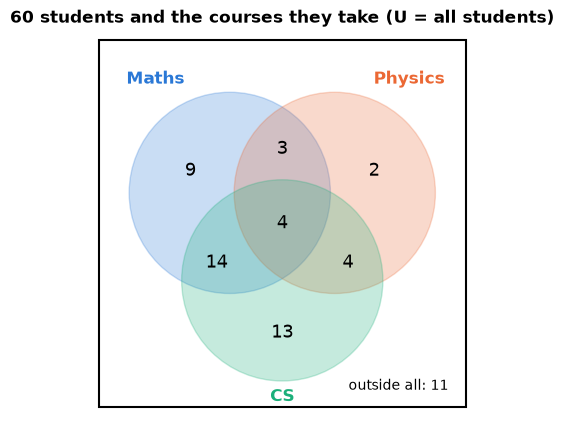

|M| = 30 |P| = 13 |C| = 35 |M ∪ P ∪ C| = 49
inclusion-exclusion gives 49


In [7]:
rng = random.Random(1)
students = range(1, 61)                                          # U = 60 students
Maths   = {s for s in students if rng.random() < 0.45}
Physics = {s for s in students if rng.random() < 0.35}
CS      = {s for s in students if rng.random() < 0.50}

def venn3(sets, names, universe, title):
    """Draw a 3-set Venn diagram whose region labels are counted from the real sets."""
    X, Y, Z = sets
    fig, ax = plt.subplots(figsize=(6, 5))
    centres = [(-0.6, 0.35), (0.6, 0.35), (0.0, -0.65)]
    name_pos = [(-1.45, 1.65), (1.45, 1.65), (0.0, -1.98)]           # set names just outside the circles
    for (cx, cy), name, colour, (nx_, ny_) in zip(centres, names, PALETTE, name_pos):
        ax.add_patch(Circle((cx, cy), 1.15, alpha=0.25, color=colour))
        ax.text(nx_, ny_, name, ha="center", va="center", fontsize=12, weight="bold", color=colour)
    regions = {   # (in X, in Y, in Z) -> label position
        (1, 0, 0): (-1.05, 0.6), (0, 1, 0): (1.05, 0.6), (0, 0, 1): (0, -1.25),
        (1, 1, 0): (0, 0.85), (1, 0, 1): (-0.75, -0.45), (0, 1, 1): (0.75, -0.45), (1, 1, 1): (0, 0.0),
    }
    for (a, b, c), (px, py) in regions.items():
        count = sum(1 for u in universe if ((u in X) == a) and ((u in Y) == b) and ((u in Z) == c))
        ax.text(px, py, str(count), ha="center", va="center", fontsize=13)
    outside = sum(1 for u in universe if u not in X | Y | Z)
    ax.text(1.9, -1.9, f"outside all: {outside}", ha="right", fontsize=10)
    ax.add_patch(plt.Rectangle((-2.1, -2.1), 4.2, 4.2, fill=False, lw=1.5))
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title)
    plt.show()

venn3([Maths, Physics, CS], ["Maths", "Physics", "CS"], students, "60 students and the courses they take (U = all students)")
print("|M| =", len(Maths), "|P| =", len(Physics), "|C| =", len(CS), "|M ∪ P ∪ C| =", len(Maths | Physics | CS))
# Inclusion-exclusion for 3 sets (proved in the combinatorics notebook):
ie = (len(Maths) + len(Physics) + len(CS) - len(Maths & Physics) - len(Maths & CS) - len(Physics & CS)
      + len(Maths & Physics & CS))
print("inclusion-exclusion gives", ie)
assert ie == len(Maths | Physics | CS)

**What just happened?** The 8 numbers inside the rectangle (7 regions plus "outside all") add up to the 60 students. The size of the union can be counted directly or by the **inclusion–exclusion principle**: add the three sets, subtract the three pairwise overlaps (counted twice), add back the triple overlap (subtracted once too often). The next notebook, [`02_combinatorics_and_recurrences.ipynb`](02_combinatorics_and_recurrences.ipynb), proves it for any number of sets.

**Complexity of Python set operations** (hash-based, see [`dsa/04` hashing](../../00_AI_Fundamentals/dsa/04_hashing.ipynb)): membership is O(1) on average; `A | B` is O(|A| + |B|); `A & B` is O(min(|A|, |B|)) on average. Building the power set is Θ(n · 2ⁿ) time and space because there are 2ⁿ subsets of average size n/2.

---
## 3. Relations and their properties

> **In plain English:** a relation is a list of which pairs are linked, and a few yes/no properties tell us what kind of link it is.

**Intuition.** A relation records which pairs of things are connected: "is a friend of", "is less than", "is a prerequisite of".

**Definition.** A **binary relation** R from A to B is any subset $R \subseteq A \times B$. We write $a\,R\,b$ for $(a, b) \in R$. A relation **on** A is a subset of $A \times A$.

Three equivalent ways to represent a relation on a finite set (all three are used in practice):

| Representation | Example for "divides" on {1, 2, 3, 4} | Good for |
|---|---|---|
| Set of pairs | {(1,1), (1,2), (1,3), (1,4), (2,2), (2,4), (3,3), (4,4)} | definitions, databases |
| Boolean matrix $M_{ij} = 1$ iff $i\,R\,j$ | see code | algorithms (Warshall), linear algebra |
| Directed graph (arrow i → j) | see plot | intuition, graph algorithms |

[(1, 1), (1, 2), (1, 3), (1, 4), (2, 2), (2, 4), (3, 3), (4, 4)]


b,1,2,3,4
a,,,,
1,1,1,1,1
2,0,1,0,1
3,0,0,1,0
4,0,0,0,1


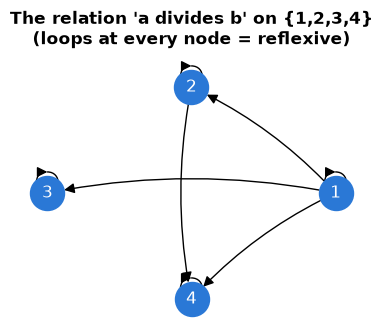

In [8]:
dom = [1, 2, 3, 4]
divides = {(a, b) for a in dom for b in dom if b % a == 0}         # a | b  ("a divides b")

def to_matrix(R, elems):
    """Boolean matrix of relation R on the ordered list `elems`."""
    idx = {e: i for i, e in enumerate(elems)}
    M = np.zeros((len(elems), len(elems)), dtype=int)
    for a, b in R:
        M[idx[a], idx[b]] = 1
    return M

print(sorted(divides))
display(pd.DataFrame(to_matrix(divides, dom), index=dom, columns=dom).rename_axis(index="a", columns="b"))

G = nx.DiGraph(); G.add_nodes_from(dom); G.add_edges_from(divides)
fig, ax = plt.subplots(figsize=(4.5, 3.5))
pos = nx.circular_layout(G)
nx.draw_networkx(G, pos, ax=ax, node_color=PALETTE[0], font_color="white", node_size=600,
                 arrowsize=15, connectionstyle="arc3,rad=0.1")
ax.set_title("The relation 'a divides b' on {1,2,3,4}\n(loops at every node = reflexive)"); ax.axis("off")
plt.show()

**Properties of a relation R on a set A.** Each is a "for all" statement, so each becomes one `all(...)` in Python:

| Property | Definition | Matrix view | Graph view |
|---|---|---|---|
| **Reflexive** | $\forall a:\ a\,R\,a$ | diagonal all 1 | loop at every node |
| **Irreflexive** | $\forall a:\ \lnot(a\,R\,a)$ | diagonal all 0 | no loops |
| **Symmetric** | $a\,R\,b \Rightarrow b\,R\,a$ | $M = M^T$ | every arrow has a return arrow |
| **Antisymmetric** | $a\,R\,b \wedge b\,R\,a \Rightarrow a = b$ | no 1 at both (i,j) and (j,i) off-diagonal | no two-way arrows between distinct nodes |
| **Asymmetric** | $a\,R\,b \Rightarrow \lnot(b\,R\,a)$ | antisymmetric + irreflexive | |
| **Transitive** | $a\,R\,b \wedge b\,R\,c \Rightarrow a\,R\,c$ | $M^2 \le M$ (Boolean product) | every 2-step path has a shortcut |

> ⚠️ **Common mistake:** "antisymmetric" is **not** "not symmetric". The relation = on any set is *both* symmetric and antisymmetric. The relation {(1,2), (2,1), (1,3)} is *neither*.

In [9]:
def is_reflexive(R, A):     return all((a, a) in R for a in A)
def is_irreflexive(R, A):   return all((a, a) not in R for a in A)
def is_symmetric(R, A):     return all((b, a) in R for (a, b) in R)
def is_antisymmetric(R, A): return all(a == b or (b, a) not in R for (a, b) in R)
def is_asymmetric(R, A):    return all((b, a) not in R for (a, b) in R)
def is_transitive(R, A):
    # for each pair (a,b) and each (b,c) that continues it, (a,c) must be in R
    succ = {}
    for a, b in R:
        succ.setdefault(a, set()).add(b)
    return all((a, c) in R for (a, b) in R for c in succ.get(b, ()))

CHECKS = [is_reflexive, is_irreflexive, is_symmetric, is_antisymmetric, is_asymmetric, is_transitive]

def properties_table(relations, A):
    rows = {}
    for name, R in relations.items():
        rows[name] = {f.__name__[3:]: "✓" if f(R, A) else "" for f in CHECKS}
    return pd.DataFrame(rows).T

A6 = range(1, 7)
pairs = list(product(A6, A6))
relations = {
    "a = b":                    {(a, b) for a, b in pairs if a == b},
    "a ≤ b":                    {(a, b) for a, b in pairs if a <= b},
    "a < b":                    {(a, b) for a, b in pairs if a < b},
    "a divides b":              {(a, b) for a, b in pairs if b % a == 0},
    "a ≡ b (mod 3)":            {(a, b) for a, b in pairs if (a - b) % 3 == 0},
    "a ≠ b":                    {(a, b) for a, b in pairs if a != b},
    "|a − b| ≤ 1 ('close to')": {(a, b) for a, b in pairs if abs(a - b) <= 1},
    "empty relation ∅":         set(),
}
properties_table(relations, A6)

,reflexive,irreflexive,symmetric,antisymmetric,asymmetric,transitive
a = b,✓,,✓,✓,,✓
a ≤ b,✓,,,✓,,✓
a < b,,✓,,✓,✓,✓
a divides b,✓,,,✓,,✓
a ≡ b (mod 3),✓,,✓,,,✓
a ≠ b,,✓,✓,,,
|a − b| ≤ 1 ('close to'),✓,,✓,,,
empty relation ∅,,✓,✓,✓,✓,✓


**What just happened?** Read the table row by row:
- **=** has every property except irreflexive and asymmetric; **≤** and **divides** are reflexive, antisymmetric and transitive: that combination is a **partial order** (Section 5).
- **<** is irreflexive, asymmetric and transitive: a **strict** partial order.
- **≡ (mod 3)** is reflexive, symmetric and transitive: an **equivalence relation** (Section 4).
- **"close to"** is reflexive and symmetric but **not transitive** (1 is close to 2 and 2 is close to 3, but 1 is not close to 3). Similarity thresholds in ML behave like this, which matters for deduplication (Section 14).
- The **empty relation** is vacuously symmetric, antisymmetric, asymmetric and transitive (there are no pairs to break the rule), but not reflexive.

**Complexity.** With R stored as a hash set, the reflexive, symmetric and antisymmetric checks are O(|A| + |R|). The transitivity check is O(Σ over pairs (a,b) of out-degree(b)) ≤ O(|R| · |A|).

🎓 **Exam / interview tip:** the number of relations on an n-element set is $2^{n^2}$ (every one of the $n^2$ pairs is in or out). The number of *reflexive* relations is $2^{n^2 - n}$ and of *symmetric* ones is $2^{n(n+1)/2}$. Practice problem 2 checks these by brute force.

---
## 4. Equivalence relations and partitions

> **In plain English:** an equivalence relation sorts things into non-overlapping bins of 'the same for my purposes'.

**Intuition.** An equivalence relation says "these two things are the same *for my purposes*": same remainder mod 3, same customer, same colour. It sorts the set into non-overlapping bins.

**Definition.** A relation is an **equivalence relation** if it is reflexive, symmetric and transitive. The **equivalence class** of a is $[a] = \{x \in A \mid x\,R\,a\}$.

A **partition** of A is a collection of non-empty, pairwise disjoint subsets ("blocks") whose union is A.

**Theorem (fundamental theorem of equivalence relations).** The equivalence classes of an equivalence relation on A form a partition of A. Conversely, every partition defines an equivalence relation ("same block"). So equivalence relations on A and partitions of A are in **one-to-one correspondence**.

*Proof sketch.* Each a is in its own class [a] (reflexive), so classes are non-empty and cover A. If two classes [a] and [b] share an element x, then x R a and x R b, so a R b by symmetry and transitivity, and then every element of [a] is in [b] and vice versa: the classes are equal. So two classes are either identical or disjoint. ∎

Worked example, mod 3 on {1, …, 10}:

| class | elements |
|---|---|
| [3] = [0] | 3, 6, 9 |
| [1] | 1, 4, 7, 10 |
| [2] | 2, 5, 8 |

In [10]:
def equivalence_classes(R, A):
    """Partition A into the classes of an equivalence relation R (asserts that R is one)."""
    assert is_reflexive(R, A) and is_symmetric(R, A) and is_transitive(R, A), "not an equivalence relation"
    classes, seen = [], set()
    for a in A:
        if a not in seen:
            cls = frozenset(x for x in A if (x, a) in R)    # [a] = {x | x R a}
            classes.append(cls)
            seen |= cls
    return classes

def relation_from_partition(blocks):
    """'Same block' relation: the other direction of the correspondence."""
    return {(x, y) for B_ in blocks for x in B_ for y in B_}

A10 = range(1, 11)
mod3 = {(a, b) for a in A10 for b in A10 if (a - b) % 3 == 0}
classes = equivalence_classes(mod3, A10)
print("classes of ≡ (mod 3):", [sorted(c) for c in classes])

# The classes really are a partition: non-empty, pairwise disjoint, union is A
assert all(classes) and set().union(*classes) == set(A10)
assert all(c1.isdisjoint(c2) for c1, c2 in combinations(classes, 2))
# ...and going partition -> relation gives back exactly the same relation
assert relation_from_partition(classes) == mod3
print("partition checks passed; partition -> relation round-trip gives back ≡ (mod 3)")

classes of ≡ (mod 3): [[1, 4, 7, 10], [2, 5, 8], [3, 6, 9]]
partition checks passed; partition -> relation round-trip gives back ≡ (mod 3)


**How many equivalence relations are there?** Because they correspond to partitions, the number on an n-element set is the number of partitions of the set, the **Bell number** $B_n$: 1, 1, 2, 5, 15, 52, 203, … (the combinatorics notebook derives these). Let us confirm for n ≤ 4 by brute force: generate *every* relation on {1, …, n} (there are $2^{n^2}$, i.e. 65,536 for n = 4) and keep those that pass the three checks.

In [11]:
def count_equivalence_relations(n):
    A_ = range(n)
    all_pairs = list(product(A_, A_))
    count = 0
    for mask in range(2 ** len(all_pairs)):                       # every subset of A×A
        R = {all_pairs[i] for i in range(len(all_pairs)) if mask >> i & 1}
        if is_reflexive(R, A_) and is_symmetric(R, A_) and is_transitive(R, A_):
            count += 1
    return count

t0 = time.perf_counter()
counts = [count_equivalence_relations(n) for n in range(1, 5)]
print("equivalence relations on n = 1..4 elements:", counts, f"({time.perf_counter() - t0:.1f} s)")
assert counts == [1, 2, 5, 15]                                    # Bell numbers B1..B4

equivalence relations on n = 1..4 elements: [1, 2, 5, 15] (1.8 s)


**What just happened?** Out of 65,536 relations on a 4-element set, exactly 15 are equivalence relations, matching the 15 ways to split 4 things into groups.

> 🎓 **Exam / interview tip:** a very common question is "is R an equivalence relation? If so, describe its classes." Check the three properties one by one, give a counterexample for any that fail, and describe the classes in words (for example, "two strings are related iff they have the same length; the classes are the sets of strings of length 0, 1, 2, …").

---
## 5. Partial orders, Hasse diagrams and topological order

> **In plain English:** a partial order says what must come before what, and a topological order is a to-do list that respects it.

**Intuition.** Some things can be compared ("2 divides 12"), some cannot (neither of 4 and 6 divides the other). A partial order is a ranking that allows ties to be "incomparable".

**Definitions.**
- A **partial order** ⪯ on A is a relation that is **reflexive, antisymmetric and transitive**. The pair (A, ⪯) is a **poset**.
- a and b are **comparable** if a ⪯ b or b ⪯ a. A **total (linear) order** is a partial order in which every pair is comparable (≤ on numbers).
- b **covers** a if a ≺ b and there is no c with a ≺ c ≺ b.
- A **Hasse diagram** draws only the covering pairs, with the larger element higher. Loops (reflexivity) and shortcuts (transitivity) are left out because they can be reconstructed.
- **Minimal / maximal** element: nothing strictly below / above it. **Least / greatest** element: below / above *everything* (at most one of each).
- **Upper bound** of a and b: some u with a ⪯ u and b ⪯ u. The **least upper bound** (join, lub) and **greatest lower bound** (meet, glb). A poset where every pair has both is a **lattice**.

Example: the divisors of 60 under "divides". The meet of two divisors is their gcd and the join is their lcm, so this poset is a lattice.

12 divisors, 42 strict pairs, but only 20 covering edges


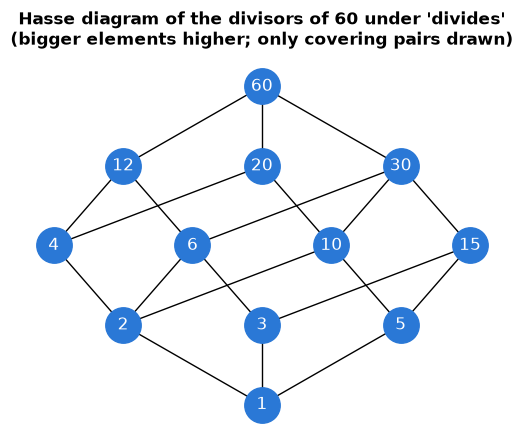

meet(12, 20) = gcd = 4 | join(12, 20) = lcm = 60
least element: 1 | greatest element: 60


In [12]:
def divisors(n):
    return [d for d in range(1, n + 1) if n % d == 0]

def hasse_edges(elems, leq):
    """Covering pairs (a, b): a < b and nothing strictly between them. O(n^3)."""
    lt = lambda a, b: a != b and leq(a, b)
    return [(a, b) for a in elems for b in elems
            if lt(a, b) and not any(lt(a, c) and lt(c, b) for c in elems)]

def big_omega(n):
    """Number of prime factors with multiplicity (used as the 'height' in the drawing)."""
    k, p = 0, 2
    while n > 1:
        while n % p == 0:
            n //= p; k += 1
        p += 1
    return k

D60 = divisors(60)
divides_leq = lambda a, b: b % a == 0
cover = hasse_edges(D60, divides_leq)

# Check against networkx: the Hasse diagram is the transitive reduction of the strict order
strict = nx.DiGraph([(a, b) for a in D60 for b in D60 if a != b and divides_leq(a, b)])
assert set(cover) == set(nx.transitive_reduction(strict).edges())
print(len(D60), "divisors,", len(strict.edges()), "strict pairs, but only", len(cover), "covering edges")

H = nx.DiGraph(cover)
levels = {}
for d in D60:
    levels.setdefault(big_omega(d), []).append(d)
pos = {d: (i - (len(row) - 1) / 2, lvl) for lvl, row in levels.items() for i, d in enumerate(row)}
fig, ax = plt.subplots(figsize=(6.5, 5))
nx.draw_networkx(H, pos, ax=ax, arrows=False, node_color=PALETTE[0], font_color="white", node_size=650)
ax.set_title("Hasse diagram of the divisors of 60 under 'divides'\n(bigger elements higher; only covering pairs drawn)")
ax.axis("off"); plt.show()

gcd_ = math.gcd; lcm_ = lambda a, b: a * b // math.gcd(a, b)
print("meet(12, 20) = gcd =", gcd_(12, 20), "| join(12, 20) = lcm =", lcm_(12, 20))
print("least element:", min(D60), "| greatest element:", max(D60))

**What just happened?** The full "divides" relation on the 12 divisors has 42 strict pairs, but the Hasse diagram needs only 20 edges: every other pair follows by transitivity. Our from-scratch `hasse_edges` agrees with networkx's `transitive_reduction`. Level 0 holds 1 (the least element), level 4 holds 60 (the greatest), and 4 and 6 sit side by side, incomparable.

### Topological order: running a task DAG
A **linear extension** of a partial order is a total order that agrees with it: whenever a ⪯ b, a comes first. For a directed acyclic graph (DAG) of tasks this is called a **topological order**: an order in which every task runs after all its prerequisites. **Every finite poset has at least one linear extension** (proof: repeatedly remove a minimal element; one always exists in a finite poset). The algorithm below is exactly that proof, known as **Kahn's algorithm** (1962).

Example: a small ML pipeline.

In [13]:
pipeline = {                       # task: set of tasks it depends on
    "download data": set(),
    "clean data": {"download data"},
    "split train/test": {"clean data"},
    "build features": {"split train/test"},
    "tune hyperparameters": {"build features"},
    "train model": {"build features", "tune hyperparameters"},
    "write data report": {"clean data"},
    "evaluate": {"train model"},
    "deploy": {"evaluate", "write data report"},
}

def topological_order(deps):
    """Kahn's algorithm: repeatedly output a task with no unfinished prerequisites. O(V + E)."""
    indeg = {t: len(d) for t, d in deps.items()}                 # unfinished prerequisites
    users = {t: [] for t in deps}
    for t, d in deps.items():
        for p in d:
            users[p].append(t)
    ready = sorted(t for t, k in indeg.items() if k == 0)        # minimal elements
    order = []
    while ready:
        t = ready.pop(0)
        order.append(t)
        for u in users[t]:
            indeg[u] -= 1
            if indeg[u] == 0:
                ready.append(u)
    if len(order) != len(deps):
        raise ValueError("cycle detected: no topological order exists")
    return order

order = topological_order(pipeline)
for i, t in enumerate(order, 1):
    print(f"{i}. {t}")
pos_in = {t: i for i, t in enumerate(order)}
assert all(pos_in[p] < pos_in[t] for t, d in pipeline.items() for p in d)

# How many valid orders are there? Count linear extensions by brute force (9! = 362,880 permutations)
DAG = nx.DiGraph([(p, t) for t, d in pipeline.items() for p in d])
def respects(perm):
    where = {t: i for i, t in enumerate(perm)}
    return all(where[p] < where[t] for p, t in DAG.edges())
n_ext = sum(1 for perm in permutations(pipeline) if respects(perm))
print("number of valid topological orders:", n_ext,
      "| networkx agrees:", n_ext == sum(1 for _ in nx.all_topological_sorts(DAG)))

try:
    topological_order({"a": {"b"}, "b": {"a"}})
except ValueError as e:
    print("cyclic dependencies ->", e)

1. download data
2. clean data
3. split train/test
4. write data report
5. build features
6. tune hyperparameters
7. train model
8. evaluate
9. deploy


number of valid topological orders: 6 | networkx agrees: True
cyclic dependencies -> cycle detected: no topological order exists


**What just happened?** Kahn's algorithm produced one valid schedule. The pipeline has more than one: "write data report" only needs clean data, so it can move to several places. The brute force found **6** valid orders (it can go in any of the 6 gaps between "clean data" and "deploy"), and networkx's `all_topological_sorts` agrees. A cycle (a needs b, b needs a) has no order at all, and the algorithm detects it because some tasks never reach in-degree 0.

**Complexity.** Kahn's algorithm with a FIFO queue is O(V + E). (Our `ready.pop(0)` on a Python list costs O(V) per pop; use `collections.deque` for the true bound.) Counting *all* linear extensions is #P-complete in general (Brightwell & Winkler, 1991), which is why we brute-forced only a 9-task example.

> 🔗 Orchestrators such as Airflow, Kubeflow and Prefect run a DAG of tasks in a topological order ([`15_MLOps/03_pipeline_orchestration`](../../15_MLOps/03_pipeline_orchestration/01_orchestration.ipynb)), and PyTorch's `loss.backward()` walks the computation graph in reverse topological order.

---
## 6. Closures and Warshall's algorithm

> **In plain English:** the transitive closure answers 'can I get from here to there in any number of steps?'.

**Intuition.** If you know "A is a direct flight from B", the **transitive closure** answers "can I get from B to A with any number of flights?".

**Definition.** The **closure** of R with respect to a property P is the *smallest* relation that contains R and has P.

| Closure | Formula | How to compute |
|---|---|---|
| Reflexive | $R \cup \{(a,a) \mid a \in A\}$ | add the diagonal |
| Symmetric | $R \cup R^{-1}$ | add every reversed pair |
| **Transitive** $R^+$ | $R \cup R^2 \cup R^3 \cup \dots$ (where $R^k$ = "connected by a path of exactly k steps") | Warshall's algorithm |

**Warshall's algorithm** (1962) works on the Boolean matrix. After step k, entry $W[i][j]$ is 1 iff there is a path from i to j whose *intermediate* nodes all lie in $\{v_1, \dots, v_k\}$. Going from step k−1 to step k, a new path appears exactly when i reaches $v_k$ and $v_k$ reaches j:

$$W^{(k)}[i][j] = W^{(k-1)}[i][j] \ \lor\ \big(W^{(k-1)}[i][k] \land W^{(k-1)}[k][j]\big).$$

That is a dynamic program over k (the same idea as Floyd–Warshall shortest paths in [`dsa/09`](../../00_AI_Fundamentals/dsa/09_dynamic_programming.ipynb), with "or/and" in place of "min/+").

In [14]:
def warshall(M, trace=False, counter=None):
    """Transitive closure of a Boolean adjacency matrix. Theta(n^3) time, Theta(n^2) space."""
    W = [row[:] for row in M]                      # copy, so the input is not modified
    n = len(W)
    snapshots = []
    for k in range(n):                             # allow node k as an intermediate stop
        for i in range(n):
            if W[i][k]:                            # i can reach k ...
                for j in range(n):
                    if counter is not None:
                        counter[0] += 1            # count basic steps (for the growth table below)
                    if W[k][j]:                    # ... and k can reach j
                        W[i][j] = 1                # so i can reach j
        if trace:
            snapshots.append([row[:] for row in W])
    return (W, snapshots) if trace else W

# Worked example: a -> b -> c -> d, and d -> b (a cycle b -> c -> d -> b)
names = ["a", "b", "c", "d"]
R = {("a", "b"), ("b", "c"), ("c", "d"), ("d", "b")}
M = to_matrix(R, names).tolist()
W, snaps = warshall(M, trace=True)
frames = [pd.DataFrame(M, index=names, columns=names)] + [pd.DataFrame(s, index=names, columns=names) for s in snaps]
labels = ["W(0) = R"] + [f"after k = {names[k]}" for k in range(4)]
for lab, df in zip(labels, frames):
    print(lab, "\n", df.to_string(), "\n")

W(0) = R 
    a  b  c  d
a  0  1  0  0
b  0  0  1  0
c  0  0  0  1
d  0  1  0  0 

after k = a 
    a  b  c  d
a  0  1  0  0
b  0  0  1  0
c  0  0  0  1
d  0  1  0  0 

after k = b 
    a  b  c  d
a  0  1  1  0
b  0  0  1  0
c  0  0  0  1
d  0  1  1  0 

after k = c 
    a  b  c  d
a  0  1  1  1
b  0  0  1  1
c  0  0  0  1
d  0  1  1  1 

after k = d 
    a  b  c  d
a  0  1  1  1
b  0  1  1  1
c  0  1  1  1
d  0  1  1  1 



**What just happened?** Read the tables in order:
- Allowing **a** as a stop adds nothing, because nothing points to a.
- Allowing **b** adds a→c (via b) and d→c (via b).
- Allowing **c** adds a→d, b→d and d→d (d→b→c→d is a cycle).
- Allowing **d** adds b→b and c→c (the cycle again) and c→b.

In the final matrix, a reaches everything else but not itself (nothing returns to a), and b, c and d each reach themselves because they lie on a cycle.

Now we test the algorithm against networkx and against the definition $R \cup R^2 \cup \dots \cup R^n$ (Boolean matrix powers) on many random relations.

In [15]:
def closure_by_powers(M):
    """R+ = R ∪ R^2 ∪ ... ∪ R^n using Boolean matrix products (slower, but straight from the definition)."""
    A_ = np.array(M, dtype=bool)
    n = len(A_)
    result, power = A_.copy(), A_.copy()
    for _ in range(n - 1):
        power = (power.astype(int) @ A_.astype(int)) > 0      # paths one step longer
        result |= power
    return result.astype(int).tolist()

rng = np.random.default_rng(0)
for trial in range(200):
    n = int(rng.integers(1, 9))
    M_ = (rng.random((n, n)) < 0.25).astype(int).tolist()
    W_ = warshall(M_)
    G_ = nx.DiGraph(); G_.add_nodes_from(range(n))
    G_.add_edges_from((i, j) for i in range(n) for j in range(n) if M_[i][j])
    TC = nx.transitive_closure(G_, reflexive=False)        # (i,i) only if i lies on a cycle
    assert {(i, j) for i in range(n) for j in range(n) if W_[i][j]} == set(TC.edges())
    assert W_ == closure_by_powers(M_)
    assert is_transitive({(i, j) for i in range(n) for j in range(n) if W_[i][j]}, range(n))
print("Warshall matches networkx.transitive_closure and R ∪ R² ∪ … ∪ Rⁿ on 200 random relations")

# Running time grows like n^3 (measured on the worst-case input)
prev = None
for n in [30, 60, 120]:
    M_ = [[1] * n for _ in range(n)]          # worst case: every entry is 1, so the `if` tests never skip work
    steps = [0]
    warshall(M_, counter=steps)               # exact count of inner-loop steps
    dt = min(timeit.repeat(lambda: warshall(M_), number=1, repeat=3))   # best of 3 reduces noise
    ratio = f"(steps × {steps[0] / prev:.0f} vs previous row)" if prev else ""
    print(f"n = {n:3d}: {steps[0]:>9,} inner steps = n³, {dt * 1000:7.1f} ms {ratio}")
    prev = steps[0]

Warshall matches networkx.transitive_closure and R ∪ R² ∪ … ∪ Rⁿ on 200 random relations
n =  30:    27,000 inner steps = n³,    21.7 ms 


n =  60:   216,000 inner steps = n³,   118.0 ms (steps × 8 vs previous row)


n = 120: 1,728,000 inner steps = n³,   916.6 ms (steps × 8 vs previous row)


**Complexity.** Three nested loops over n nodes give **Θ(n³)** time and Θ(n²) space (the matrix). For a sparse graph, running BFS from every node is O(n · (n + |E|)), which is faster when |E| is much smaller than n². Doubling n multiplies the number of inner steps by exactly 2³ = 8, as the table shows. Wall-clock times follow the same trend, but they are noisy on a busy machine, which is why algorithm analysis counts steps rather than seconds. The **reflexive-transitive closure** $R^*$ (used in "reachability", and in regular expressions as the Kleene star, see [notebook 04](04_automata_and_regular_languages.ipynb)) is $R^+ \cup$ the diagonal.

---
## 7. Functions: injective, surjective, bijective

> **In plain English:** a function gives exactly one output per input; we ask whether outputs collide (injective) and whether every output is reachable (surjective).

**Intuition.** A function is a machine that takes any allowed input and gives exactly **one** output. A vending machine is a function from button to snack; a phone book that lists two numbers for one person is *not* a function.

**Definition.** A **function** $f: A \to B$ is a relation $f \subseteq A \times B$ in which every $a \in A$ is related to **exactly one** $b \in B$, written $f(a) = b$. A is the **domain**, B the **codomain**, and $f(A) = \{f(a) \mid a \in A\}$ the **range** (or image).

| Kind | Definition | Picture | Counting consequence (finite sets) |
|---|---|---|---|
| **Injective** (one-to-one) | $f(a_1) = f(a_2) \Rightarrow a_1 = a_2$ | no two arrows hit the same target | $\lvert A \rvert \le \lvert B \rvert$ |
| **Surjective** (onto) | $\forall b \in B\ \exists a: f(a) = b$ | every target is hit | $\lvert A \rvert \ge \lvert B \rvert$ |
| **Bijective** | injective and surjective | a perfect pairing | $\lvert A \rvert = \lvert B \rvert$ |

A function has an **inverse** $f^{-1}: B \to A$ (with $f^{-1}(f(a)) = a$ and $f(f^{-1}(b)) = b$) **iff it is bijective**. The **composition** $(g \circ f)(a) = g(f(a))$ means "apply f first, then g".

In Python a finite function is naturally a `dict` (keys = domain, values = outputs).

In [16]:
def is_function(R, A, B):
    """Is the relation R ⊆ A×B a function from A to B (every a has exactly one image in B)?"""
    return all(sum(1 for (x, y) in R if x == a) == 1 for a in A) and all(y in B for (_, y) in R)

def is_injective(f):                   # f is a dict
    return len(set(f.values())) == len(f)

def is_surjective(f, B):
    return set(f.values()) == set(B)

def is_bijective(f, B):
    return is_injective(f) and is_surjective(f, B)

def inverse(f):
    assert is_injective(f), "only an injective function can be inverted (on its range)"
    return {v: k for k, v in f.items()}

def compose(g, f):
    """(g ∘ f)(x) = g(f(x)): apply f first."""
    return {x: g[f[x]] for x in f}

print("phone book with two numbers for Ali is a function?",
      is_function({("Ali", 111), ("Ali", 222), ("Sara", 333)}, {"Ali", "Sara"}, {111, 222, 333}))

examples = {
    "square on {-2..2} -> {0,1,4}":   ({x: x * x for x in range(-2, 3)}, {0, 1, 4}),
    "x+1 on {0..4} -> {0..5}":        ({x: x + 1 for x in range(5)}, set(range(6))),
    "x mod 3 on {0..5} -> {0,1,2}":   ({x: x % 3 for x in range(6)}, {0, 1, 2}),
    "2x on {0..4} -> {0,2,4,6,8}":    ({x: 2 * x for x in range(5)}, {0, 2, 4, 6, 8}),
}
rows = []
for name, (f, B_) in examples.items():
    rows.append({"function": name, "injective": is_injective(f), "surjective": is_surjective(f, B_),
                 "bijective": is_bijective(f, B_)})
display(pd.DataFrame(rows).set_index("function"))

f = {x: 2 * x for x in range(5)}                 # bijection {0..4} -> {0,2,4,6,8}
g = {y: y + 1 for y in f.values()}               # y -> y + 1
print("g∘f =", compose(g, f), "| f⁻¹ =", inverse(f))
assert all(inverse(f)[f[x]] == x for x in f)     # f⁻¹(f(x)) = x

phone book with two numbers for Ali is a function? False


,injective,surjective,bijective
function,,,
"square on {-2..2} -> {0,1,4}",False,True,False
x+1 on {0..4} -> {0..5},True,False,False
"x mod 3 on {0..5} -> {0,1,2}",False,True,False
"2x on {0..4} -> {0,2,4,6,8}",True,True,True


g∘f = {0: 1, 1: 3, 2: 5, 3: 7, 4: 9} | f⁻¹ = {0: 0, 2: 1, 4: 2, 6: 3, 8: 4}


**Counting functions.** For finite sets with $|A| = m$ and $|B| = n$:
- the number of functions $A \to B$ is $n^m$ (each of the m inputs picks one of n outputs);
- the number of injections is $n(n-1)\cdots(n-m+1) = \dfrac{n!}{(n-m)!}$ (each input must pick an unused output);
- the number of bijections, when $m = n$, is $n!$.

The surjection count needs inclusion–exclusion and is derived in the next notebook. Let us check these formulas, and two classic facts about composition, by listing *every* function between small sets.

In [17]:
def all_functions(A, B):
    """Every function A -> B as a dict: one choice of output per input (itertools.product)."""
    A, B = list(A), list(B)
    return [dict(zip(A, outs)) for outs in product(B, repeat=len(A))]

rows = []
for m, n in [(2, 3), (3, 3), (3, 4), (4, 3)]:
    fs = all_functions(range(m), range(n))
    rows.append({"|A|": m, "|B|": n, "functions": len(fs), "n^m": n ** m,
                 "injections": sum(map(is_injective, fs)), "n!/(n-m)!": math.perm(n, m) if m <= n else 0,
                 "bijections": sum(is_bijective(f_, range(n)) for f_ in fs)})
display(pd.DataFrame(rows))

# Composition facts, checked on all pairs f: X->Y, g: Y->Z with |X| = |Y| = |Z| = 3
X = Y = Z = range(3)
F, Gs = all_functions(X, Y), all_functions(Y, Z)
assert all(is_injective(compose(g_, f_)) for f_ in F for g_ in Gs if is_injective(f_) and is_injective(g_))
assert all(is_surjective(compose(g_, f_), Z) for f_ in F for g_ in Gs if is_surjective(f_, Y) and is_surjective(g_, Z))
print("checked on", len(F) * len(Gs), "pairs: injective∘injective is injective; surjective∘surjective is surjective")

,|A|,|B|,functions,n^m,injections,n!/(n-m)!,bijections
0,2,3,9,9,6,6,0
1,3,3,27,27,6,6,6
2,3,4,64,64,24,24,0
3,4,3,81,81,0,0,0


checked on 729 pairs: injective∘injective is injective; surjective∘surjective is surjective


**What just happened?** Every count matches its formula: for example 4 inputs into 3 outputs gives $3^4 = 81$ functions, none of them injective. That is the **pigeonhole principle** (4 pigeons, 3 holes: two must share), which the next notebook uses to explain hash collisions.

> ⚠️ **Common mistake:** confusing **codomain** and **range**. $f(x) = x^2$ from $\mathbb{R}$ to $\mathbb{R}$ has codomain $\mathbb{R}$ but range $[0, \infty)$; it is not surjective. The same rule from $\mathbb{R}$ to $[0, \infty)$ *is* surjective. Whether a function is onto depends on the codomain you declare.

---
## 8. Cardinality and countability

> **In plain English:** two sets are the same size if you can pair them up perfectly, and some infinite sets are bigger than others.

**Definition.** Two sets have the **same cardinality**, $|A| = |B|$, if there is a bijection between them. This works for infinite sets too, and gives surprising answers.

A set is **countable** if it is finite or has the same cardinality as $\mathbb{N}$ ("countably infinite"): you can list its elements as a sequence $a_0, a_1, a_2, \dots$ that eventually reaches every element. Otherwise it is **uncountable**.

1. **$\mathbb{Z}$ is countable.** List it as 0, 1, −1, 2, −2, 3, … The bijection $\mathbb{N} \to \mathbb{Z}$ is $f(n) = n/2$ if n is even, $-(n+1)/2$ if n is odd. (Infinite sets can be put in bijection with a proper subset of themselves; finite sets cannot.)
2. **$\mathbb{N} \times \mathbb{N}$ is countable.** Walk the grid of pairs along diagonals. The **Cantor pairing function** $\pi(x, y) = \frac{(x+y)(x+y+1)}{2} + y$ is a bijection $\mathbb{N}^2 \to \mathbb{N}$. Since every fraction p/q is a pair, **$\mathbb{Q}$ is countable** too.
3. **$\mathbb{R}$ is uncountable** (Cantor, 1891, the **diagonal argument**). Suppose someone claims a complete list $s_0, s_1, s_2, \dots$ of all infinite binary sequences (each one is a real number in [0, 1] written in binary). Build a new sequence d by flipping the diagonal: the i-th bit of d is the *opposite* of the i-th bit of $s_i$. Then d differs from $s_0$ in bit 0, from $s_1$ in bit 1, and so on: d is not in the list. So *no* list is complete.

```
s0 = 0 1 1 0 1 ...        diagonal bits: 0, 0, 1, 1, ...
s1 = 1 0 0 1 0 ...        flipped:       1, 1, 0, 0, ...  = d
s2 = 0 1 1 1 0 ...
s3 = 1 1 0 1 1 ...        d differs from every s_i at position i
```

In [18]:
# 1. A bijection N -> Z, checked on a finite prefix
to_Z = lambda n: n // 2 if n % 2 == 0 else -(n + 1) // 2
print("N -> Z:", [to_Z(n) for n in range(11)])
assert sorted(to_Z(n) for n in range(2001)) == list(range(-1000, 1001))

# 2. Cantor pairing N x N -> N and its inverse
def pair(x, y):
    return (x + y) * (x + y + 1) // 2 + y

def unpair(z):
    w = (math.isqrt(8 * z + 1) - 1) // 2          # which diagonal x + y = w
    y = z - w * (w + 1) // 2
    return w - y, y

codes = [pair(x, y) for x in range(60) for y in range(60) if x + y < 60]
assert sorted(codes) == list(range(len(codes)))               # hits 0, 1, 2, ... with no gaps or repeats
assert all(unpair(pair(x, y)) == (x, y) for x in range(200) for y in range(200))
print("first pairs in Cantor order:", [unpair(z) for z in range(10)])

# 3. The diagonal argument as code: for ANY list of sequences, build one that is not in it
def diagonal_escape(seqs):
    return [1 - seqs[i][i] for i in range(len(seqs))]

rng_ = random.Random(3)
claimed_list = [[rng_.randint(0, 1) for _ in range(8)] for _ in range(8)]
d = diagonal_escape(claimed_list)
for i, s in enumerate(claimed_list):
    print(f"s{i} = {''.join(map(str, s))}   differs from d at position {i}: {s[i]} vs {d[i]}")
print("d  =", "".join(map(str, d)), "| d in list?", d in claimed_list)

N -> Z: [0, -1, 1, -2, 2, -3, 3, -4, 4, -5, 5]


first pairs in Cantor order: [(0, 0), (1, 0), (0, 1), (2, 0), (1, 1), (0, 2), (3, 0), (2, 1), (1, 2), (0, 3)]
s0 = 00110011   differs from d at position 0: 0 vs 1
s1 = 00111000   differs from d at position 1: 0 vs 1
s2 = 10000101   differs from d at position 2: 0 vs 1
s3 = 11111010   differs from d at position 3: 1 vs 0
s4 = 00101111   differs from d at position 4: 1 vs 0
s5 = 11101010   differs from d at position 5: 0 vs 1
s6 = 10011001   differs from d at position 6: 0 vs 1
s7 = 10101001   differs from d at position 7: 1 vs 0
d  = 11100110 | d in list? False


**Cantor's theorem.** The same trick shows $|A| < |\mathcal{P}(A)|$ for *every* set A, finite or infinite. Given any function $f: A \to \mathcal{P}(A)$, the "diagonal" set $D = \{x \in A \mid x \notin f(x)\}$ cannot equal any $f(a)$: if $D = f(a)$, then $a \in D \iff a \notin f(a) = D$, a contradiction. So no f is onto. For a 3-element set we can check this against *all* $8^3 = 512$ functions.

In [19]:
A3 = [0, 1, 2]
PA3 = power_set(A3)                                   # 8 subsets
n_checked = 0
for f_ in all_functions(A3, PA3):
    D_ = frozenset(x for x in A3 if x not in f_[x])   # Cantor's diagonal set
    assert D_ not in f_.values()                      # D is never hit, so f is not surjective
    n_checked += 1
print(f"checked all {n_checked} functions A -> P(A): the diagonal set D is never in the range")

checked all 512 functions A -> P(A): the diagonal set D is never in the range


**What just happened?** For every one of the 512 functions, the diagonal set D was missing from the range. This is the same idea as the diagonal-flip above, and the same idea that proves the **halting problem** undecidable (no program can decide whether every program halts; the grammars-and-computability notebook, [`05_grammars_parsing_and_computability.ipynb`](05_grammars_parsing_and_computability.ipynb), covers it).

🎓 **Exam / interview tip:** the set of all Python programs is countable (each program is a finite string over a finite alphabet, and you can list strings by length), but the set of all functions $\mathbb{N} \to \{0, 1\}$ is uncountable. So **most functions cannot be computed by any program**.

---
## 9. Quantifiers (a short recap)

> **In plain English:** 'for all' and 'there exists' are `all()` and `any()`, and swapping their order changes the meaning.

Mathematical statements are full of "for all" and "there exists". Full predicate logic is in [`classical_ai/07`, Section 10](../../00_AI_Fundamentals/classical_ai/07_knowledge_representation_and_logic.ipynb); here is what proofs need.

| Symbol | Meaning | On a finite domain, in Python | To disprove it, show… |
|---|---|---|---|
| $\forall x\, P(x)$ | P holds for every x | `all(P(x) for x in D)` | one counterexample |
| $\exists x\, P(x)$ | P holds for at least one x | `any(P(x) for x in D)` | P fails for every x |

**Negation rules (De Morgan for quantifiers):** $\lnot \forall x\, P(x) \equiv \exists x\, \lnot P(x)$ and $\lnot \exists x\, P(x) \equiv \forall x\, \lnot P(x)$.

**Order matters.** $\forall x\, \exists y\ (x + y \equiv 0 \pmod 5)$ says "every x has its own inverse y" (true). $\exists y\, \forall x\ (x + y \equiv 0)$ says "one y works for every x" (false).

In [20]:
D5 = range(5)                                          # integers mod 5
P = lambda x, y: (x + y) % 5 == 0
print("∀x ∃y  x+y ≡ 0 (mod 5):", all(any(P(x, y) for y in D5) for x in D5))
print("∃y ∀x  x+y ≡ 0 (mod 5):", any(all(P(x, y) for x in D5) for y in D5))

# Negation rule: not (for all x, x < 4)  ==  exists x with not (x < 4)
Q = lambda x: x < 4
assert (not all(Q(x) for x in D5)) == any(not Q(x) for x in D5)
print("¬∀x P(x) ≡ ∃x ¬P(x) checked; the witness is", [x for x in D5 if not Q(x)])

∀x ∃y  x+y ≡ 0 (mod 5): True
∃y ∀x  x+y ≡ 0 (mod 5): False
¬∀x P(x) ≡ ∃x ¬P(x) checked; the witness is [4]


---
## 10. Proof techniques

> **In plain English:** a proof is a step-by-step argument that covers every case; here are the five standard ways to build one.

A **proof** is a chain of logically valid steps from accepted facts (definitions, axioms, earlier theorems) to the claim. Tests can find bugs, but only a proof covers *all* (often infinitely many) cases. Most statements have the form "if P then Q" ($P \Rightarrow Q$). Here are the standard ways to prove one.

| Technique | Structure | Use when |
|---|---|---|
| **Direct** | assume P, derive Q | P gives you something concrete to compute with |
| **Contrapositive** | prove $\lnot Q \Rightarrow \lnot P$ (logically equivalent) | $\lnot Q$ is easier to work with than P |
| **Contradiction** | assume P and $\lnot Q$, derive something false | the claim is "X is impossible / irrational / infinite" |
| **Cases** | split into exhaustive cases, prove each | parity, sign, remainders |
| **Counterexample** | exhibit one x where the claim fails | *disproving* a "for all" claim |
| **Induction** | base case + step $P(k) \Rightarrow P(k+1)$ | claims about all n ≥ n₀ (Section 11) |

Recall the definitions used below: n is **even** if $n = 2k$ for some integer k, and **odd** if $n = 2k + 1$.

### 10.1 Direct proof
**Claim.** The sum of two odd integers is even.

**Proof.** Let $a = 2j + 1$ and $b = 2k + 1$ for integers j, k. Then $a + b = 2j + 2k + 2 = 2(j + k + 1)$, which is 2 times an integer, so it is even. ∎

### 10.2 Proof by contrapositive
**Claim.** If $n^2$ is even, then n is even.

A direct attempt gets stuck ("$n^2 = 2k$, so $n = \sqrt{2k}$…"). The **contrapositive** is "if n is odd, then $n^2$ is odd", which is easy.

**Proof.** Suppose n is odd, $n = 2k + 1$. Then $n^2 = 4k^2 + 4k + 1 = 2(2k^2 + 2k) + 1$, which is odd. Since the contrapositive holds, so does the claim. ∎

> ⚠️ **Common mistake:** proving the **converse** $Q \Rightarrow P$ instead. "If n is even then $n^2$ is even" is a different statement. The contrapositive $\lnot Q \Rightarrow \lnot P$ is equivalent to $P \Rightarrow Q$; the converse is not.

### 10.3 Proof by contradiction
**Claim.** $\sqrt{2}$ is irrational.

**Proof.** Suppose not: $\sqrt{2} = p/q$ with integers p, q > 0 and the fraction in lowest terms (no common factor). Then $p^2 = 2q^2$, so $p^2$ is even, so p is even by 10.2: $p = 2r$. Then $4r^2 = 2q^2$, so $q^2 = 2r^2$ is even, so q is even. Now p and q are both even, contradicting "lowest terms". ∎

**Claim (Euclid, c. 300 BC).** There are infinitely many primes.

**Proof.** Suppose there are finitely many, $p_1, \dots, p_k$. Let $N = p_1 p_2 \cdots p_k + 1$. Dividing N by any $p_i$ leaves remainder 1, so no $p_i$ divides N. But N > 1 has some prime factor (Section 11.2), which must then be a prime not in the list. Contradiction. ∎

(Note: N itself need not be prime. 2·3·5·7·11·13 + 1 = 30031 = 59 · 509.)

### 10.4 Proof by cases
**Claim.** For every integer n, $n^2 + n$ is even.

**Proof.** $n^2 + n = n(n + 1)$. *Case 1:* n even, so the factor n is even and so is the product. *Case 2:* n odd, so n + 1 is even and so is the product. The cases cover all integers. ∎

### 10.5 Disproof by counterexample
**Claim (false).** $n^2 + n + 41$ is prime for every natural number n. (Euler noticed this polynomial gives primes for a long time.)

### 10.6 Set equality by element-chasing (De Morgan)
**Claim.** $\overline{A \cup B} = \overline{A} \cap \overline{B}$.

**Proof.** Show each side is a subset of the other. ($\subseteq$) Let $x \in \overline{A \cup B}$. Then $x \notin A \cup B$, so x is in neither A nor B, so $x \in \overline{A}$ and $x \in \overline{B}$, so $x \in \overline{A} \cap \overline{B}$. ($\supseteq$) Every step above is reversible. ∎

In [21]:
def is_prime(n):
    if n < 2:
        return False
    return all(n % d for d in range(2, math.isqrt(n) + 1))

# Testing gives evidence, never proof. Evidence for 10.1 - 10.4:
assert all((a + b) % 2 == 0 for a in range(-51, 52, 2) for b in range(-51, 52, 2))    # odd + odd is even
assert all(n % 2 == 0 for n in range(-1000, 1001) if (n * n) % 2 == 0)                 # n^2 even => n even
assert all((n * n + n) % 2 == 0 for n in range(-1000, 1001))                            # n^2 + n even
print("Euclid's N = 2·3·5·7·11·13 + 1 =", 2 * 3 * 5 * 7 * 11 * 13 + 1, "= 59 ×", 30031 // 59,
      "| prime?", is_prime(30031))

# 10.5: hunt for a counterexample to "n^2 + n + 41 is always prime"
first_fail = next(n for n in range(1000) if not is_prime(n * n + n + 41))
v = first_fail ** 2 + first_fail + 41
print(f"n² + n + 41 is prime for n = 0..{first_fail - 1}, but n = {first_fail} gives {v} = {math.isqrt(v)}²")

Euclid's N = 2·3·5·7·11·13 + 1 = 30031 = 59 × 509 | prime? False
n² + n + 41 is prime for n = 0..39, but n = 40 gives 1681 = 41²


**What just happened?** The polynomial produced primes for 40 consecutive values (n = 0 … 39) and then failed at n = 40, giving $1681 = 41^2$. This is the classic warning: **40 passing tests did not prove the claim.** A single counterexample disproved it.

> 🎓 **Exam / interview tip:** start every proof by writing down the definitions in symbols ("n is odd means n = 2k + 1"). Most first-year proofs then take three lines. And end with what you proved ("so a + b is even ∎"), so the grader can see the chain is complete.

---
## 11. Mathematical induction and strong induction

> **In plain English:** induction proves a statement for every number: show it for the first one, then show each case pushes over the next.

**Intuition: dominoes.** If (1) the first domino falls, and (2) any falling domino knocks over the next one, then *all* dominoes fall.

**Principle of mathematical induction.** To prove $P(n)$ for all integers $n \ge n_0$:
1. **Base case:** prove $P(n_0)$.
2. **Inductive step:** for an arbitrary $k \ge n_0$, assume $P(k)$ (the **inductive hypothesis**, IH) and prove $P(k+1)$.

Induction is valid because of the **well-ordering principle**: every non-empty set of natural numbers has a least element. (If P failed somewhere, take the smallest failure m. It is not $n_0$ by the base case, so $P(m-1)$ holds, and then the step gives $P(m)$: contradiction.)

### 11.1 Worked examples (ordinary induction)
**Claim A (Gauss's sum).** $1 + 2 + \dots + n = \dfrac{n(n+1)}{2}$ for all $n \ge 1$.
- *Base* n = 1: left side 1, right side 1·2/2 = 1. ✓
- *Step:* assume $1 + \dots + k = k(k+1)/2$. Then $1 + \dots + k + (k+1) = \frac{k(k+1)}{2} + (k+1) = \frac{(k+1)(k+2)}{2}$, which is the formula for k + 1. ∎

**Claim B (geometric series).** $\sum_{i=0}^{n} 2^i = 2^{n+1} - 1$. *Base* n = 0: 1 = 2 − 1. *Step:* $(2^{k+1} - 1) + 2^{k+1} = 2^{k+2} - 1$. ∎ (This is why a full binary tree of height h has $2^{h+1} - 1$ nodes.)

**Claim C (an inequality, base case not at 0).** $2^n > n^2$ for all $n \ge 5$.
- *Base* n = 5: 32 > 25. ✓
- *Step:* assume $2^k > k^2$ with $k \ge 5$. Then $2^{k+1} = 2 \cdot 2^k > 2k^2$. We need $2k^2 \ge (k+1)^2$, i.e. $k^2 \ge 2k + 1$, which holds for $k \ge 3$ because $k^2 - 2k - 1 = (k-1)^2 - 2 \ge 2 > 0$. So $2^{k+1} > (k+1)^2$. ∎

(For n = 2, 3, 4 the claim is false: 4 > 4, 8 > 9 and 16 > 16 all fail. Choosing the right base case matters.)

In [22]:
rows = []
for n in range(0, 9):
    rows.append({"n": n, "1+…+n": sum(range(1, n + 1)), "n(n+1)/2": n * (n + 1) // 2,
                 "Σ 2^i (i ≤ n)": sum(2 ** i for i in range(n + 1)), "2^(n+1) − 1": 2 ** (n + 1) - 1,
                 "2^n": 2 ** n, "n²": n * n, "2^n > n²?": 2 ** n > n * n})
display(pd.DataFrame(rows).set_index("n"))
assert all(sum(range(1, n + 1)) == n * (n + 1) // 2 for n in range(2000))
assert all(2 ** n > n * n for n in range(5, 500))

,1+…+n,n(n+1)/2,Σ 2^i (i ≤ n),2^(n+1) − 1,2^n,n²,2^n > n²?
n,,,,,,,
0,0,0,1,1,1,0,True
1,1,1,3,3,2,1,True
2,3,3,7,7,4,4,False
3,6,6,15,15,8,9,False
4,10,10,31,31,16,16,False
5,15,15,63,63,32,25,True
6,21,21,127,127,64,36,True
7,28,28,255,255,128,49,True
8,36,36,511,511,256,64,True


The table shows 2ⁿ > n² is true at n = 0 and 1, false at n = 2, 3 and 4, and true from n = 5 on, exactly as the proof's base case says.

### 11.2 Strong induction
In the step of **strong induction** you may assume $P(n_0), P(n_0+1), \dots, P(k)$ (all earlier cases), not only $P(k)$. It is equally valid (and equivalent in power), and it is the natural tool when $k + 1$ breaks into pieces much smaller than k.

**Claim D (fundamental theorem of arithmetic, existence part).** Every integer $n \ge 2$ is a product of primes.
- *Base* n = 2: 2 is prime. ✓
- *Step:* assume every integer from 2 to k is a product of primes. Look at k + 1. If it is prime, done. Otherwise $k + 1 = a \cdot b$ with $2 \le a, b \le k$. By the strong IH, a and b are products of primes, so their product is too. ∎

**Claim E (postage).** Every amount $n \ge 12$ cents can be paid with 4-cent and 5-cent stamps.
- *Bases* n = 12, 13, 14, 15: 4+4+4, 4+4+5, 4+5+5, 5+5+5. ✓
- *Step* (k + 1 ≥ 16): by the strong IH, k + 1 − 4 = k − 3 ≥ 12 can be paid; add one 4-cent stamp. ∎

A constructive proof *is* a recursive algorithm. Below, each function follows its proof line by line, so the code is "correct by construction".

In [23]:
def prime_factors(n):
    """Mirrors the strong-induction proof of Claim D."""
    for a in range(2, math.isqrt(n) + 1):
        if n % a == 0:                           # n = a * b, both smaller than n
            return prime_factors(a) + prime_factors(n // a)
    return [n]                                   # no divisor found: n is prime (base / prime case)

def stamps(n):
    """Mirrors the proof of Claim E: four base cases, then 'pay n - 4, add a 4'."""
    base = {12: [4, 4, 4], 13: [4, 4, 5], 14: [4, 5, 5], 15: [5, 5, 5]}
    if n in base:
        return base[n]
    return stamps(n - 4) + [4]

print("360 =", " × ".join(map(str, prime_factors(360))))
print("31 cents =", " + ".join(map(str, stamps(31))))
for n in range(2, 3000):
    fs = prime_factors(n)
    assert math.prod(fs) == n and all(is_prime(p) for p in fs)
for n in range(12, 500):
    s = stamps(n)
    assert sum(s) == n and set(s) <= {4, 5}
print("both constructive proofs checked: n = 2..2999 factored, n = 12..499 cents paid")

360 = 2 × 2 × 2 × 3 × 3 × 5
31 cents = 5 + 5 + 5 + 4 + 4 + 4 + 4


both constructive proofs checked: n = 2..2999 factored, n = 12..499 cents paid


> ⚠️ **Common mistake: the "all horses are the same colour" fallacy (Pólya).** "Claim: in any group of n horses, all have the same colour. Base n = 1: trivially true. Step: take k + 1 horses; remove horse 1, the remaining k are the same colour by IH; remove horse k + 1 instead, those k are the same colour; the two groups overlap, so all k + 1 match." The bug: for k = 1 (going from 1 horse to 2), the two groups {horse 2} and {horse 1} do **not** overlap. The step must work for *every* k ≥ n₀, including the smallest one. Always test your step on the first transition.

🎓 **Exam / interview tip:** state the IH explicitly ("Assume P(k) holds for some arbitrary k ≥ n₀"), point out the exact place you use it ("by the IH"), and make sure your base case is the n₀ the step needs (Claim C needs n₀ = 5, Claim E needs four base cases because the step jumps back by 4).

---
## 12. Loop invariants: proving algorithms correct

> **In plain English:** a loop invariant is a fact that stays true every time round a loop, which is how we prove code is correct.

A **loop invariant** is a statement that is true before every iteration of a loop. Proving it is induction over the number of iterations (CLRS ch. 2):

| Step | Meaning | Induction analogue |
|---|---|---|
| **Initialization** | true before the first iteration | base case |
| **Maintenance** | if true before an iteration, still true after it | inductive step |
| **Termination** | when the loop ends, the invariant plus the exit condition gives the result | conclusion |

To show the loop *ends* at all, give a **variant**: a natural number that strictly decreases every iteration (it cannot decrease forever, by well-ordering).

**Example 1: insertion sort.** Invariant: *at the start of iteration j, the prefix `a[0..j-1]` contains the original first j elements, in sorted order.* Initialization: j = 1, a one-element prefix is sorted. Maintenance: the inner loop shifts larger elements right and drops `a[j]` into place, so `a[0..j]` is sorted. Termination: j = n, so the whole array is sorted.

**Example 2: Euclid's algorithm.** Invariant: $\gcd(a, b)$ never changes, because $\gcd(a, b) = \gcd(b, a \bmod b)$. Variant: b decreases strictly (since $a \bmod b < b$). At termination b = 0 and $\gcd(a, 0) = a$.

**Example 3: fast exponentiation.** Invariant: $\text{result} \cdot \text{base}^{\text{e}} = x^n$. Variant: e halves each step.

Below, the invariants are checked with `assert` at run time on many inputs. This is how you turn a proof idea into a guard in real code (and how property-based tests work).

In [24]:
def insertion_sort_checked(a):
    a = list(a)
    original = list(a)
    for j in range(1, len(a) + 1):
        # INVARIANT: a[:j] is the sorted version of original[:j]
        assert a[:j] == sorted(original[:j]), "invariant broken"
        if j == len(a):
            break
        key, i = a[j], j - 1
        while i >= 0 and a[i] > key:          # shift larger elements one step right
            a[i + 1] = a[i]
            i -= 1
        a[i + 1] = key
    return a

def gcd_checked(a, b):
    g = math.gcd(a, b)                        # used only to CHECK the invariant
    while b != 0:
        assert math.gcd(a, b) == g            # INVARIANT: gcd unchanged
        old_b = b
        a, b = b, a % b
        assert 0 <= b < old_b                 # VARIANT: b strictly decreases
    return a

def power_checked(x, n):
    result, base, e = 1, x, n
    while e > 0:
        assert result * base ** e == x ** n   # INVARIANT
        if e % 2 == 1:
            result *= base
        base *= base
        e //= 2                               # VARIANT: e halves
    assert result == x ** n
    return result

rng = random.Random(7)
for _ in range(300):
    arr = [rng.randint(-50, 50) for _ in range(rng.randint(0, 15))]
    assert insertion_sort_checked(arr) == sorted(arr)
    a_, b_ = rng.randint(0, 10**6), rng.randint(0, 10**6)
    assert gcd_checked(a_, b_) == math.gcd(a_, b_)
    x_, n_ = rng.randint(-9, 9), rng.randint(0, 40)
    assert power_checked(x_, n_) == x_ ** n_
print("invariants held on 300 random runs of each algorithm")
print("gcd(1071, 462) =", gcd_checked(1071, 462), "| 3^13 =", power_checked(3, 13))

# What a broken loop looks like: an off-by-one bug breaks the invariant and the assert catches it
def buggy_sort(a):
    a = list(a); original = list(a)
    for j in range(1, len(a) + 1):
        assert a[:j] == sorted(original[:j]), f"invariant broken at j = {j}: prefix {a[:j]}"
        if j == len(a):
            break
        key, i = a[j], j - 1
        while i > 0 and a[i] > key:           # BUG: should be i >= 0 (never compares with a[0])
            a[i + 1] = a[i]; i -= 1
        a[i + 1] = key
    return a
try:
    buggy_sort([3, 1, 2])
except AssertionError as e:
    print("caught:", e)

invariants held on 300 random runs of each algorithm
gcd(1071, 462) = 21 | 3^13 = 1594323


caught: invariant broken at j = 2: prefix [3, 1]


**What just happened?** All three invariants held on hundreds of random inputs, and the deliberate off-by-one bug (`i > 0` instead of `i >= 0`) was caught the moment the invariant failed: after the first insertion the prefix was [3, 1], not sorted.

**Complexity of the checked versions.** The `assert` lines are for teaching: the insertion-sort check re-sorts the prefix every iteration, which turns O(n²) into O(n² log n). In production you prove the invariant once on paper and leave the cheap checks (or none) in the code.

> 🎓 **Exam / interview tip:** "prove binary search is correct" is a standard question. Invariant: *if the target is in the array, it is in `a[lo..hi]`*. Variant: `hi − lo` shrinks every iteration. Practice problem 7 asks you to write and check it.

---
## 13. Summary table

> **In plain English:** everything in this notebook on one page.

| Concept | Definition in one line | Key fact / formula | Code in this notebook |
|---|---|---|---|
| Power set | all subsets | $\lvert\mathcal{P}(A)\rvert = 2^n$ | `power_set` (bitmasks) |
| Cartesian product | all ordered pairs | $\lvert A \times B\rvert = \lvert A\rvert\lvert B\rvert$ | `cartesian` |
| Relation | subset of $A \times B$ | $2^{n^2}$ relations on an n-set | `to_matrix`, property checkers |
| Equivalence relation | reflexive + symmetric + transitive | ⇔ partition; count = Bell number | `equivalence_classes` |
| Partial order | reflexive + antisymmetric + transitive | drawn as Hasse diagram; has a linear extension | `hasse_edges`, `topological_order` |
| Transitive closure | smallest transitive superset | Warshall Θ(n³) | `warshall` |
| Function | each input → exactly one output | $n^m$ functions, $n!/(n-m)!$ injections | `is_injective`, `compose`, `inverse` |
| Countable | bijection with ℕ (or finite) | ℤ, ℚ, ℕ×ℕ countable; ℝ, 𝒫(ℕ) not | `pair`, `diagonal_escape` |
| Induction | base + step | justified by well-ordering | `stamps`, `prime_factors` |
| Loop invariant | induction over iterations | initialization, maintenance, termination | `insertion_sort_checked` |

---
## 14. 🔗 How this connects to modern AI

> **In plain English:** these ideas are hiding inside search metrics, data cleaning, ML pipelines and model design.

| Idea from this notebook | Where it shows up in AI systems |
|---|---|
| Set operations | **Retrieval metrics**: precision = $\lvert\text{retrieved} \cap \text{relevant}\rvert / \lvert\text{retrieved}\rvert$, recall = $\lvert\text{retrieved} \cap \text{relevant}\rvert / \lvert\text{relevant}\rvert$ ([`08_LLM/02_rag/01_rag_fundamentals.ipynb`](../../08_LLM/02_rag/01_rag_fundamentals.ipynb)). **Jaccard similarity** $\lvert A \cap B\rvert / \lvert A \cup B\rvert$ for near-duplicate detection (MinHash estimates it). Vocabularies and label sets. |
| Equivalence classes | **Deduplication / entity resolution**: "same customer" must be an equivalence relation, so pairwise matches are closed transitively (union-find) into clusters. But "similarity ≥ 0.9" is *not* transitive, so chaining can merge very different records: a real data-cleaning bug. |
| Partial orders, topological order | Pipelines and **task DAGs** (Airflow, Kubeflow, [`15_MLOps/03`](../../15_MLOps/03_pipeline_orchestration/01_orchestration.ipynb)); **autograd** runs backward in reverse topological order of the computation graph ([`05_Deep_Learning/01`](../../05_Deep_Learning/01_neural_network_fundamentals.ipynb)); build systems; LLM agents planning sub-tasks with dependencies. |
| Transitive closure | Reachability queries in **knowledge graphs** ("is a mammal an animal?" through a chain of is-a edges), recursive SQL (`WITH RECURSIVE`) ([`08_LLM/09_knowledge_graphs`](../../08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb)). |
| Functions | A trained **model is a function** $h: \mathcal{X} \to \mathcal{Y}$ from a hypothesis class. A **hash** or an **embedding** into a smaller space cannot be injective (pigeonhole), so collisions are guaranteed. A **tokenizer**'s encode must be injective so that decode can invert it (round-trip tests check `decode(encode(s)) == s`). |
| Countability | Programs (and finite neural networks with finite-precision weights) form a countable set, while functions are uncountable: most functions are not computable or learnable exactly, which motivates inductive bias. |
| Induction, invariants | Correctness proofs of algorithms used in ML infrastructure; **property-based testing**; formal verification of neural-network properties; LLM + proof assistants (Lean) for mathematics. |

A tiny demonstration of the first two rows:

In [25]:
retrieved = {"doc1", "doc3", "doc4", "doc7"}
relevant = {"doc1", "doc2", "doc3"}
tp = retrieved & relevant
print(f"precision = {len(tp)}/{len(retrieved)} = {len(tp) / len(retrieved):.2f}, "
      f"recall = {len(tp)}/{len(relevant)} = {len(tp) / len(relevant):.2f}, "
      f"Jaccard = {len(tp) / len(retrieved | relevant):.2f}")

# Entity resolution: pairwise "same person" decisions -> equivalence classes via union-find
records = ["Ali Khan", "ali khan", "A. Khan", "Sara Ahmed", "S. Ahmed", "Bilal"]
matches = [(0, 1), (1, 2), (3, 4)]                     # pairs a matcher said are the same person
parent = list(range(len(records)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]                  # path halving
        x = parent[x]
    return x
for a, b in matches:
    parent[find(a)] = find(b)                          # union
clusters = {}
for i in range(len(records)):
    clusters.setdefault(find(i), []).append(records[i])
print("entities:", list(clusters.values()))

precision = 2/4 = 0.50, recall = 2/3 = 0.67, Jaccard = 0.40
entities: [['Ali Khan', 'ali khan', 'A. Khan'], ['Sara Ahmed', 'S. Ahmed'], ['Bilal']]


**What just happened?** Precision and recall are just set sizes. Union-find took three pairwise decisions and closed them under transitivity (0~1 and 1~2 give 0~2), producing three entities: an equivalence relation built from a few examples. Union-find is analysed in [`advanced_algorithms/01`](../../00_AI_Fundamentals/advanced_algorithms/01_amortized_and_randomized_algorithms.ipynb).

---
## 15. Recap

> **In plain English:** the key facts to remember, then practice.

- A **set** is an unordered collection of distinct elements. Know ∪, ∩, −, ⊕, complement, the laws (De Morgan!) and how to prove $A = B$ by showing $A \subseteq B$ and $B \subseteq A$. $|\mathcal{P}(A)| = 2^n$ and $|A \times B| = |A||B|$.
- A **relation** is a set of pairs; check **reflexive, symmetric, antisymmetric, transitive** one by one. Antisymmetric ≠ not symmetric.
- **Equivalence relations** (refl. + sym. + trans.) correspond exactly to **partitions** into equivalence classes.
- **Partial orders** (refl. + antisym. + trans.) are drawn as **Hasse diagrams**; every finite poset has a **linear extension** (topological order), found by Kahn's algorithm in O(V + E).
- The **transitive closure** is the smallest transitive relation containing R; **Warshall's algorithm** computes it in Θ(n³).
- A **function** maps every input to exactly one output. **Injective** = no collisions, **surjective** = hits everything, **bijective** = both = invertible. There are $n^m$ functions and $n!/(n-m)!$ injections from an m-set to an n-set.
- ℤ, ℚ and ℕ×ℕ are **countable**; ℝ and 𝒫(ℕ) are **uncountable** (Cantor's **diagonal argument**), and $|A| < |\mathcal{P}(A)|$ always.
- Proof techniques: **direct, contrapositive, contradiction, cases, counterexample**. Testing is evidence; a proof is a guarantee.
- **Induction** (base + step) and **strong induction** (assume all earlier cases) rest on well-ordering. **Loop invariants** apply induction to loops: initialization, maintenance, termination, plus a decreasing variant for termination.

## Practice problems

**1. (Easy, conceptual + coding)** Prove that $A \oplus B = (A \cup B) - (A \cap B)$ by element-chasing, then check it by brute force over all pairs of subsets of {1, 2, 3, 4}.

<details><summary>Show solution</summary>

*Proof.* $x \in A \oplus B$ ⇔ x is in exactly one of A, B ⇔ (x ∈ A or x ∈ B) and not (x ∈ A and x ∈ B) ⇔ $x \in (A \cup B) - (A \cap B)$. ∎

```python
def check(U):
    """True iff X ⊕ Y == (X ∪ Y) − (X ∩ Y) for every pair of subsets X, Y of U."""
    from itertools import combinations
    subs = [frozenset(c) for r in range(len(U) + 1) for c in combinations(sorted(U), r)]
    return all((X - Y) | (Y - X) == (X | Y) - (X & Y) for X in subs for Y in subs)

print(check({1, 2, 3, 4}))   # True
```

</details>

**2. (Easy)** How many relations, reflexive relations and symmetric relations are there on an n-element set? Derive the formulas, then verify for n = 1, 2, 3 by brute force.

<details><summary>Show solution</summary>

All relations: each of the $n^2$ pairs is in or out, so $2^{n^2}$. Reflexive: the n diagonal pairs are forced in, the other $n^2 - n$ are free: $2^{n^2-n}$. Symmetric: choose freely the n diagonal pairs and one decision for each of the $\binom{n}{2}$ unordered off-diagonal pairs $\{(a,b),(b,a)\}$: $2^{n + n(n-1)/2} = 2^{n(n+1)/2}$.

```python
from itertools import product

def count_relations(n):
    A = range(n)
    pairs = list(product(A, A))
    refl = sym = 0
    for mask in range(2 ** len(pairs)):
        R = {pairs[i] for i in range(len(pairs)) if mask >> i & 1}
        refl += all((a, a) in R for a in A)
        sym += all((b, a) in R for (a, b) in R)
    return 2 ** (n * n), refl, sym

for n in range(1, 4):
    total, refl, sym = count_relations(n)
    assert (total, refl, sym) == (2 ** (n * n), 2 ** (n * n - n), 2 ** (n * (n + 1) // 2))
    print(n, total, refl, sym)     # 1 2 1 2 | 2 16 4 8 | 3 512 64 64
```

</details>

**3. (Easy, conceptual)** On the set of all people, is "has the same birthday as" an equivalence relation? Is "is an ancestor of" a partial order? Is "is at most 2 cm taller than" transitive?

<details><summary>Show solution</summary>

- Same birthday: reflexive, symmetric, transitive, so **yes**, an equivalence relation with (at most) 366 classes.
- Ancestor of: irreflexive (nobody is their own ancestor), asymmetric and transitive, so it is a **strict** partial order. "Is an ancestor of or equal to" is a partial order.
- "At most 2 cm taller": not transitive. A = 174 cm, B = 172.5 cm, C = 171 cm: A is 1.5 cm taller than B and B is 1.5 cm taller than C, but A is 3 cm taller than C. Like the "close to" relation in Section 3.

</details>

**4. (Medium, proof)** Prove by induction that $\sum_{i=1}^{n} i^2 = \dfrac{n(n+1)(2n+1)}{6}$ for all $n \ge 1$.

<details><summary>Show solution</summary>

*Base* n = 1: 1 = 1·2·3/6. ✓ *Step:* assume it for k. Then
$\sum_{i=1}^{k+1} i^2 = \frac{k(k+1)(2k+1)}{6} + (k+1)^2 = \frac{(k+1)\,[k(2k+1) + 6(k+1)]}{6} = \frac{(k+1)(2k^2 + 7k + 6)}{6} = \frac{(k+1)(k+2)(2k+3)}{6}$,
which is the formula with n = k + 1. ∎ Quick check: `all(sum(i*i for i in range(1, n+1)) == n*(n+1)*(2*n+1)//6 for n in range(1, 1000))` is `True`.

</details>

**5. (Medium, coding)** Write `is_partial_order(R, A)` and use it to show that ⊆ on the power set of {1, 2, 3} is a partial order but not a total order. What do its Hasse diagram's levels correspond to?

<details><summary>Show solution</summary>

```python
def is_partial_order(R, A):
    refl = all((a, a) in R for a in A)
    anti = all(a == b or (b, a) not in R for (a, b) in R)
    trans = all((a, d) in R for (a, b) in R for (c, d) in R if b == c)
    return refl and anti and trans

from itertools import combinations
U = [1, 2, 3]
subsets = [frozenset(c) for r in range(4) for c in combinations(U, r)]
subset_order = {(X, Y) for X in subsets for Y in subsets if X <= Y}
print(is_partial_order(subset_order, subsets))                      # True
# not total: {1} and {2} are incomparable
print(any((X, Y) not in subset_order and (Y, X) not in subset_order
          for X in subsets for Y in subsets))                       # True
```
The Hasse diagram of $(\mathcal{P}(\{1,2,3\}), \subseteq)$ is a **cube**: level k holds the $\binom{3}{k}$ subsets of size k (1, 3, 3, 1 nodes), and each edge adds one element.

</details>

**6. (Medium, proof)** Prove that if $f: A \to B$ and $g: B \to C$ are both injective, then $g \circ f$ is injective. Is the converse true (if $g \circ f$ is injective, must both be)?

<details><summary>Show solution</summary>

*Proof.* Suppose $g(f(a_1)) = g(f(a_2))$. Since g is injective, $f(a_1) = f(a_2)$. Since f is injective, $a_1 = a_2$. ∎

*Converse:* false. If $g \circ f$ is injective then **f** must be injective (if $f(a_1) = f(a_2)$ then $g(f(a_1)) = g(f(a_2))$ so $a_1 = a_2$), but g need not be. Counterexample: A = {0}, B = {0, 1}, C = {0}, f(0) = 0, g(0) = g(1) = 0. Then $g \circ f$ (one input) is injective, but g is not.

</details>

**7. (Hard, coding + proof)** Write binary search with its loop invariant checked by `assert`, state the variant, and test it on 500 random cases (including targets that are absent).

<details><summary>Show solution</summary>

```python
def binary_search(a, target):
    """Return an index of target in sorted list a, or -1. Invariant: if target is in a, it is in a[lo:hi]."""
    lo, hi = 0, len(a)
    while lo < hi:
        assert target not in a[:lo] and target not in a[hi:]   # invariant (expensive check, for teaching)
        mid = (lo + hi) // 2
        if a[mid] == target:
            return mid
        if a[mid] < target:
            lo = mid + 1          # target, if present, is right of mid
        else:
            hi = mid              # target, if present, is left of mid
    return -1                     # a[lo:hi] is empty, so by the invariant target is not in a

import random
rng = random.Random(0)
for _ in range(500):
    a = sorted(rng.sample(range(100), rng.randint(0, 20)))
    t = rng.randint(-5, 105)
    i = binary_search(a, t)
    assert (i == -1 and t not in a) or a[i] == t
print("binary search correct on 500 random tests")
```
*Variant:* `hi − lo` is a natural number that strictly decreases each iteration (`lo = mid + 1 > lo` or `hi = mid < hi`, because lo ≤ mid < hi), so the loop terminates. At termination the invariant and `lo == hi` give "target not in a".

</details>

**8. (Hard, coding)** ℚ⁺ is countable. Using `unpair` from Section 8, write `nth_positive_rational(n)` that lists every positive fraction exactly once (in lowest terms). What are the first 10?

<details><summary>Show solution</summary>

```python
def unpair(z):
    import math
    w = (math.isqrt(8 * z + 1) - 1) // 2
    y = z - w * (w + 1) // 2
    return w - y, y

def nth_positive_rational(n):
    """Enumerate positive fractions p/q in lowest terms with no repeats, using Cantor's diagonals."""
    import math
    seen = 0
    z = 0
    while True:
        x, y = unpair(z)
        p, q = x + 1, y + 1                    # shift so p, q >= 1
        if math.gcd(p, q) == 1:                # skip 2/4 etc. (already listed as 1/2)
            if seen == n:
                return p, q
            seen += 1
        z += 1

print([f"{p}/{q}" for p, q in (nth_positive_rational(i) for i in range(10))])
```
Output: `['1/1', '2/1', '1/2', '3/1', '1/3', '4/1', '3/2', '2/3', '1/4', '5/1']`. Skipping fractions not in lowest terms removes the repeats (2/2, 2/4, …), so the listing is a bijection ℕ → ℚ⁺.

</details>

## Further reading

- K. H. Rosen, *Discrete Mathematics and Its Applications*, 8th ed. (2019): ch. 1 (logic and proofs), ch. 2 (sets, functions, cardinality), ch. 5 (induction), ch. 9 (relations).
- E. Lehman, F. T. Leighton and A. R. Meyer, *Mathematics for Computer Science* (MIT, free PDF; course MIT 6.1200J, formerly 6.042J, on MIT OpenCourseWare): chapters on proofs, induction, sets, relations and infinite sets.
- D. J. Velleman, *How to Prove It*, 3rd ed. (2019): the best book for learning to write proofs.
- T. H. Cormen et al., *Introduction to Algorithms* (CLRS), 4th ed. (2022), §2.1: loop invariants.

## Next notebook

➡️ [`02_combinatorics_and_recurrences.ipynb`](02_combinatorics_and_recurrences.ipynb): counting without listing (permutations, combinations, the pigeonhole principle, inclusion–exclusion), solving recurrences, generating functions, and Catalan and Stirling numbers.